# Housing luxury classification with logistic regression

Examine whether bedroom and bathroom counts help classify the luxury indicator in the course housing dataset. Compare the fitted models, evaluate held-out classifications and inspect model assumptions. This classification question is separate from predicting sale price.


## Load the housing data


In [2]:
# Logistic Regression

#Importing Libraries
import pandas as pd # pandas for data manipulation and analysis


#Importing Dataset
file_path = r"../data/housing_data.csv"

# Read the CSV file into a DataFrame
df = pd.read_csv(file_path)

# Display the first few rows of the DataFrame to understand its structure
display(df.head())


,ID,Price,SquareFootage,NumBathrooms,NumBedrooms,BackyardSpace,CrimeRate,SchoolRating,AgeOfHome,DistanceToCityCenter,...,RenovationQuality,LocalAmenities,TransportAccess,Fireplace,HouseColor,Garage,Floors,Windows,PreviousSalePrice,IsLuxury
0,4922,255614.8992,566.62,1.000000,4,779.42,20.56,5.62,39.46,10.08,...,4.93,4.44,4.55,Yes,Blue,No,1,13,181861.54230,0
1,5009,155586.0947,1472.34,1.000000,2,656.13,15.62,5.63,40.51,7.89,...,4.08,5.56,6.83,No,Green,No,1,17,50042.59757,0
2,4450,131050.8324,550.00,1.779354,3,754.57,12.47,9.20,48.38,23.74,...,4.26,8.07,8.48,Yes,Green,Yes,2,34,48400.34440,0
3,1070,151361.7125,941.81,2.035254,2,439.59,22.22,7.08,94.67,5.22,...,4.45,5.00,6.27,Yes,Red,No,1,14,84594.12145,0
4,400,113167.6128,550.00,1.064644,3,353.03,8.28,5.93,16.80,43.13,...,3.36,5.46,6.99,No,White,Yes,1,21,22934.59654,0


## Explore predictors and the outcome


In [3]:
#Descriptive statistics
variable_columns = ['NumBathrooms', 'NumBedrooms', 'IsLuxury']
stats = df[variable_columns].describe()

# Display the results
display(stats)

,NumBathrooms,NumBedrooms,IsLuxury
count,7000.000000,7000.000000,7000.00000
mean,2.131397,3.008571,0.50400
std,0.952561,1.021940,0.50002
min,1.000000,1.000000,0.00000
25%,1.290539,2.000000,0.00000
50%,1.997774,3.000000,1.00000
75%,2.763997,4.000000,1.00000
max,5.807239,7.000000,1.00000


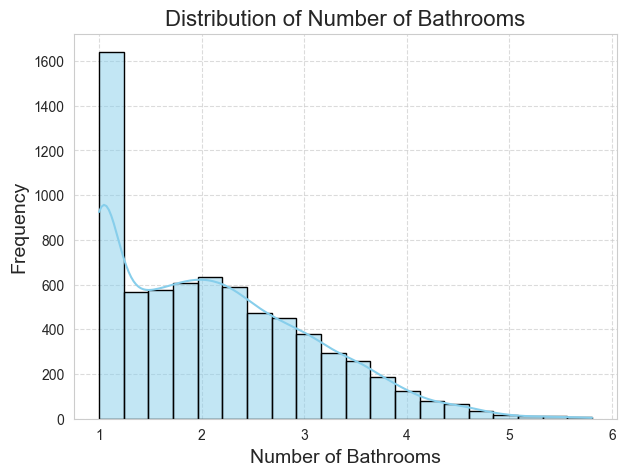

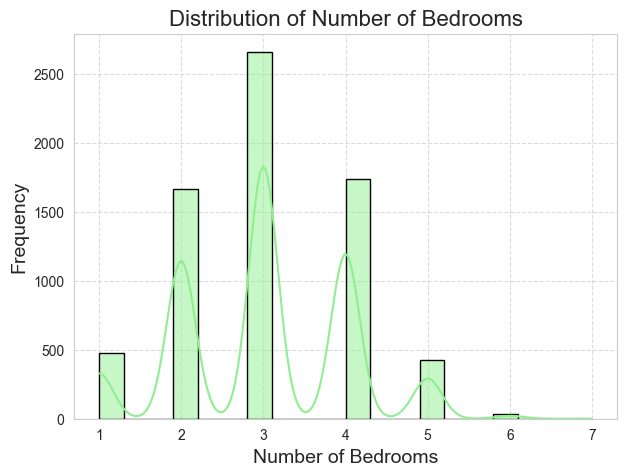

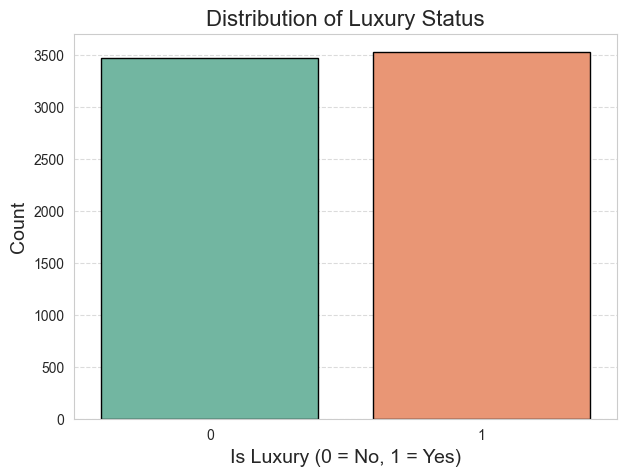

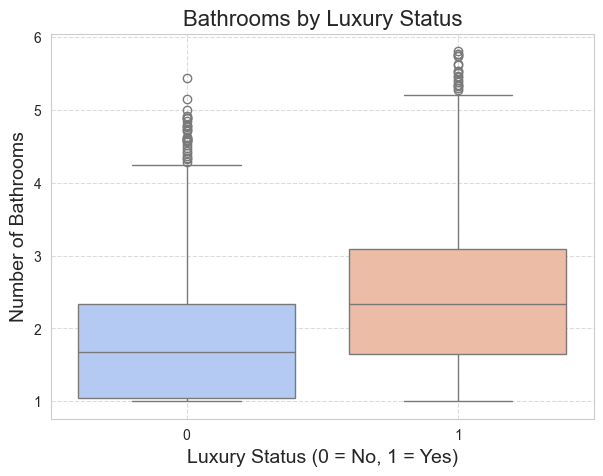

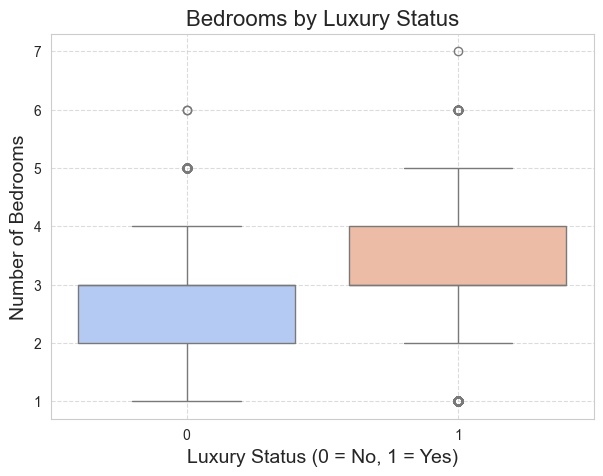

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a brighter overall style
sns.set_style("whitegrid")

# Univariate: Histogram for NumBathrooms
plt.figure(figsize=(7,5))
sns.histplot(df['NumBathrooms'], bins=20, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribution of Number of Bathrooms', fontsize=16)
plt.xlabel('Number of Bathrooms', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Univariate: Histogram for NumBedrooms
plt.figure(figsize=(7,5))
sns.histplot(df['NumBedrooms'], bins=20, kde=True, color='lightgreen', edgecolor='black')
plt.title('Distribution of Number of Bedrooms', fontsize=16)
plt.xlabel('Number of Bedrooms', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Univariate: Bar plot for IsLuxury
plt.figure(figsize=(7,5))
sns.countplot(x='IsLuxury', hue='IsLuxury', data=df, palette='Set2', edgecolor='black', legend=False)
plt.title('Distribution of Luxury Status', fontsize=16)
plt.xlabel('Is Luxury (0 = No, 1 = Yes)', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()

# Bivariate: Boxplot of NumBathrooms vs IsLuxury
plt.figure(figsize=(7,5))
sns.boxplot(x='IsLuxury', y='NumBathrooms', data=df, hue='IsLuxury', palette='coolwarm', legend=False)
plt.title('Bathrooms by Luxury Status', fontsize=16)
plt.xlabel('Luxury Status (0 = No, 1 = Yes)', fontsize=14)
plt.ylabel('Number of Bathrooms', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

# Bivariate: Boxplot of NumBedrooms vs IsLuxury
plt.figure(figsize=(7,5))
sns.boxplot(x='IsLuxury', y='NumBedrooms', data=df, hue='IsLuxury', palette='coolwarm', legend=False)
plt.title('Bedrooms by Luxury Status', fontsize=16)
plt.xlabel('Luxury Status (0 = No, 1 = Yes)', fontsize=14)
plt.ylabel('Number of Bedrooms', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()


## Split the data


In [5]:
from sklearn.model_selection import train_test_split

# 1. Select only the needed variables
selected_columns = ['NumBedrooms', 'NumBathrooms', 'IsLuxury']
df_selected = df[selected_columns]

# 2. Train-test split (80% train, 20% test)
train_df, test_df = train_test_split(df_selected, test_size=0.2, random_state=42)

print("Training and test datasets created successfully in memory.")

Training and test datasets created successfully in memory.


## Fit and compare logistic models


In [6]:
import statsmodels.api as sm

# 1. Use the in-memory training split created above
X_train = train_df[['NumBedrooms', 'NumBathrooms']]
y_train = train_df['IsLuxury']

# 2. Add constant term (for intercept)
X_train = sm.add_constant(X_train)

# 3. Build the logistic regression model
logit_model = sm.Logit(y_train, X_train)
result = logit_model.fit()

# 4. Print full summary (Pseudo R², p-values, coefficients)
print(result.summary())

# 5. Manually print AIC and BIC
print("\nAdditional Model Information:")
print(f"AIC: {result.aic}")
print(f"BIC: {result.bic}")


Optimization terminated successfully.
         Current function value: 0.596619
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:               IsLuxury   No. Observations:                 5600
Model:                          Logit   Df Residuals:                     5597
Method:                           MLE   Df Model:                            2
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.1392
Time:                        07:58:19   Log-Likelihood:                -3341.1
converged:                       True   LL-Null:                       -3881.2
Covariance Type:            nonrobust   LLR p-value:                2.678e-235
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -3.4940      0.125    -27.874      0.000      -3.740      -3.248
NumBedrooms      0.6966

In [7]:
# Optimization

# 1. Build full logistic regression model
X_full = train_df[['NumBedrooms', 'NumBathrooms']]
y = train_df['IsLuxury']

X_full_const = sm.add_constant(X_full)
full_model = sm.Logit(y, X_full_const).fit()

# 2. Show full model summary
print("\nFull Model Summary:")
print(full_model.summary())

# 3. Fit a one-predictor comparison using bathrooms only.
# Both predictors remain in the final model; this comparison is not the selected model.
X_reduced = train_df[['NumBathrooms']]  # Drop NumBedrooms
X_reduced_const = sm.add_constant(X_reduced)
reduced_model = sm.Logit(y, X_reduced_const).fit()

# 4. Show reduced model summary
print("\nReduced Model Summary:")
print(reduced_model.summary())

Optimization terminated successfully.
         Current function value: 0.596619
         Iterations 5

Full Model Summary:
                           Logit Regression Results                           
Dep. Variable:               IsLuxury   No. Observations:                 5600
Model:                          Logit   Df Residuals:                     5597
Method:                           MLE   Df Model:                            2
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                  0.1392
Time:                        07:58:19   Log-Likelihood:                -3341.1
converged:                       True   LL-Null:                       -3881.2
Covariance Type:            nonrobust   LLR p-value:                2.678e-235
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -3.4940      0.125    -27.874      0.000      -3.740      -3.248
Nu

## Evaluate classification performance


In [8]:
from sklearn.metrics import confusion_matrix, accuracy_score

# 1. Predict on the training set
# Predict probabilities
y_train_pred_probs = result.predict(X_train)

# Convert probabilities to 0 or 1 using 0.5 threshold
y_train_pred = (y_train_pred_probs >= 0.5).astype(int)

# 2. Confusion matrix
cm = confusion_matrix(y_train, y_train_pred)
print("Confusion Matrix:")
print(cm)

# 3. Accuracy
accuracy = accuracy_score(y_train, y_train_pred)
print("\nAccuracy on Training Set:", round(accuracy, 4))


Confusion Matrix:
[[1956  809]
 [ 944 1891]]

Accuracy on Training Set: 0.687


In [9]:
# 1. Use the in-memory test split created above
X_test = test_df[['NumBedrooms', 'NumBathrooms']]
X_test = sm.add_constant(X_test)  # Add constant for intercept

# 2. Define y_test
y_test = test_df['IsLuxury']

# 3. Predict probabilities
y_test_pred_probs = result.predict(X_test)

# 4. Convert probabilities to 0 or 1 using 0.5 threshold
y_test_pred = (y_test_pred_probs >= 0.5).astype(int)

# 5. Confusion matrix
from sklearn.metrics import confusion_matrix, accuracy_score

cm_test = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix (Test Set):")
print(cm_test)

# 6. Accuracy
accuracy_test = accuracy_score(y_test, y_test_pred)
print("\nAccuracy on Test Set:", round(accuracy_test, 4))


Confusion Matrix (Test Set):
[[472 235]
 [224 469]]

Accuracy on Test Set: 0.6721


# Verification of Assumptions

In [10]:
# Check unique values in IsLuxury
print(train_df['IsLuxury'].value_counts())

IsLuxury
1    2835
0    2765
Name: count, dtype: int64


In [11]:
# Check for duplicate rows
print(train_df.duplicated().sum())

929


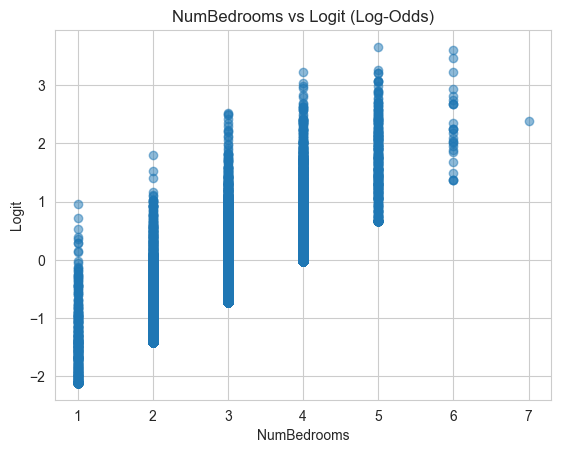

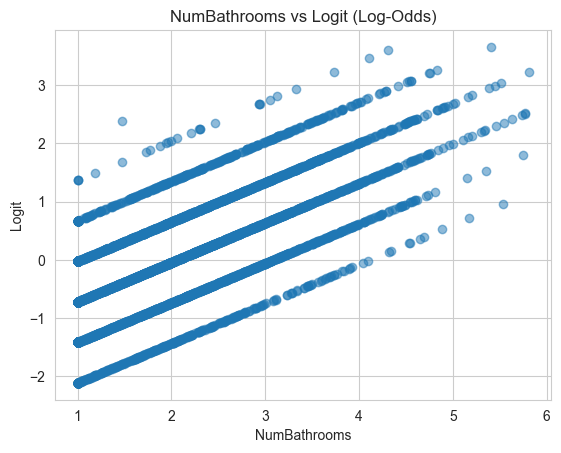

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Get predicted probabilities
train_pred_probs = result.predict(X_train)

# Create logit (log-odds)
logit = np.log(train_pred_probs / (1 - train_pred_probs))

# Plot NumBedrooms vs logit
plt.scatter(train_df['NumBedrooms'], logit, alpha=0.5)
plt.title('NumBedrooms vs Logit (Log-Odds)')
plt.xlabel('NumBedrooms')
plt.ylabel('Logit')
plt.grid(True)
plt.show()

# Plot NumBathrooms vs logit
plt.scatter(train_df['NumBathrooms'], logit, alpha=0.5)
plt.title('NumBathrooms vs Logit (Log-Odds)')
plt.xlabel('NumBathrooms')
plt.ylabel('Logit')
plt.grid(True)
plt.show()


In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['Feature'] = X_train.columns
vif_data['VIF'] = [variance_inflation_factor(X_train.values, i) for i in range(X_train.shape[1])]

print(vif_data)


        Feature        VIF
0         const  13.325999
1   NumBedrooms   1.009851
2  NumBathrooms   1.009851
